# Mushroom Classification — Machine Learning Assignment 2

Name : Rajesh Kovvuru
Bits ID : 2026AJ05562

## 1. Install and import dependencies

In [1]:
# %pip install -U pandas numpy scikit-learn matplotlib seaborn joblib streamlit

import os
import json
import warnings
import platform
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TARGET = "class"
PROJECT_DIR = Path.cwd()
MODEL_DIR = PROJECT_DIR / "model"
MODEL_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", version("scikit-learn"))

Python: 3.9.6
pandas: 2.3.3
NumPy: 2.0.2
scikit-learn: 1.6.1


## 2. Load and validate the dataset

In [2]:
DATA_PATH = PROJECT_DIR / "train.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Download the Mushroom Classification CSV and save it as 'mushrooms.csv' "
        "in the same folder as this notebook, or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

if TARGET not in df.columns:
    raise ValueError(f"Expected target column '{TARGET}'. Found: {df.columns.tolist()}")

if len(df) < 500 or df.shape[1] - 1 < 12:
    raise ValueError("Dataset does not meet the assignment minimum of 500 rows and 12 input features.")

print("\nTarget counts:")
display(df[TARGET].value_counts(dropna=False).to_frame("count"))

Dataset shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,p,w,o,e,n,a,g


Columns: ['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Target counts:


,count
class,
e,4208
p,3916


## 3. Data quality checks and exploratory analysis

The source dataset commonly represents unknown values in `stalk-root` with `?`. These are treated as missing values. Imputation is placed inside each model pipeline so that imputation and encoding are learned from training data only, avoiding data leakage.

Dataset shape: (8124, 23)
Duplicate rows: 0

Missing values by column:


,missing_count
stalk-root,2480
stalk-surface-above-ring,0
population,0
spore-print-color,0
ring-type,0
ring-number,0
veil-color,0
veil-type,0
stalk-color-below-ring,0
stalk-color-above-ring,0



Data types:


,column_count
object,23


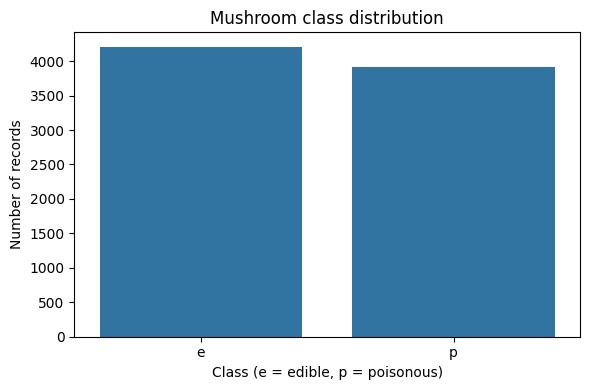

Unique values per feature:


,unique_values
veil-type,1
bruises,2
gill-attachment,2
gill-spacing,2
gill-size,2
stalk-shape,2
ring-number,3
cap-surface,4
veil-color,4
stalk-surface-above-ring,4


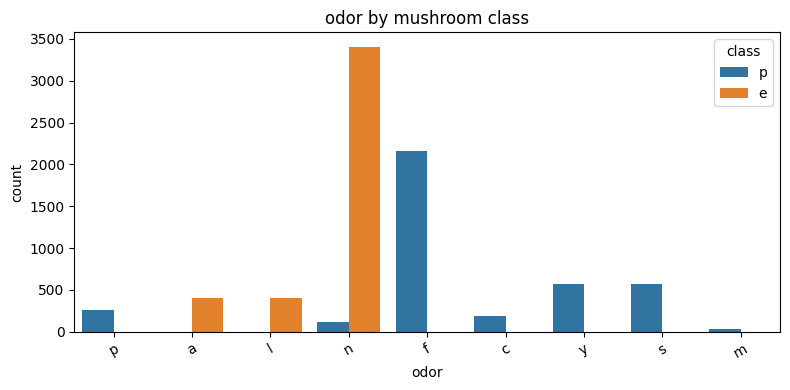

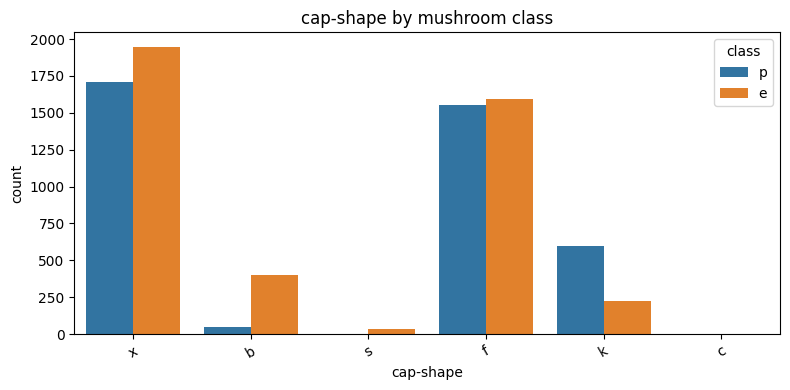

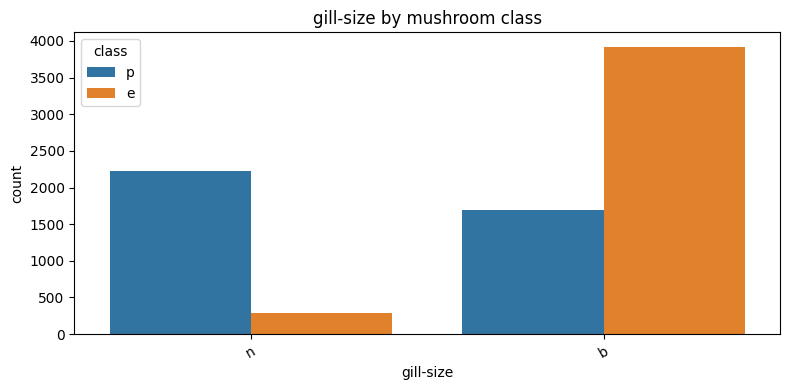

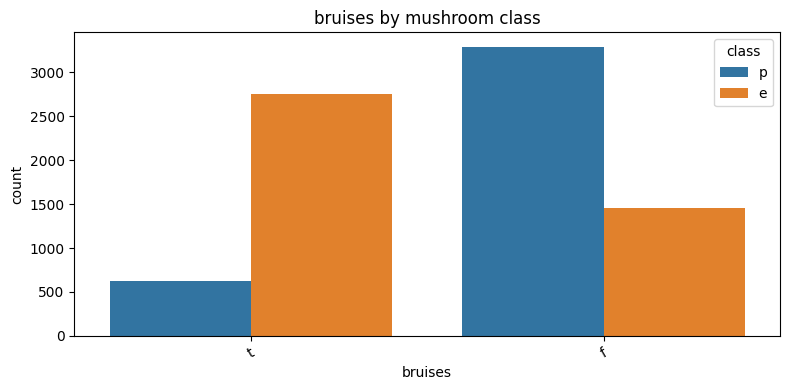

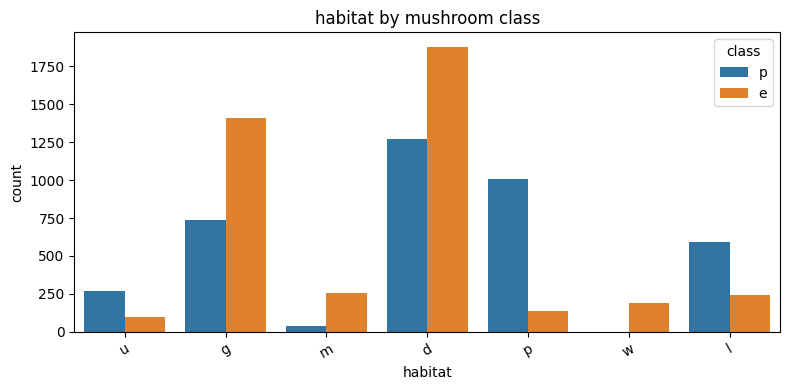

In [3]:
df = df.copy()
df = df.replace(["?", "", "NA", "NaN"], np.nan)

print("Dataset shape:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nData types:")
display(df.dtypes.astype(str).value_counts().to_frame("column_count"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET, order=sorted(df[TARGET].dropna().unique()))
plt.title("Mushroom class distribution")
plt.xlabel("Class (e = edible, p = poisonous)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

print("Unique values per feature:")
display(df.drop(columns=TARGET).nunique(dropna=False).sort_values().to_frame("unique_values"))


selected_features = [c for c in ["odor", "cap-shape", "gill-size", "bruises", "habitat"] if c in df.columns]
for feature in selected_features:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=feature, hue=TARGET)
    plt.title(f"{feature} by mushroom class")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

## 4. Prepare target, features, and remove constant columns

Target encoding is fixed as `0 = edible (e)` and `1 = poisonous (p)`. Therefore, precision, recall, F1, and MCC treat poisonous mushrooms as the positive class. The target is validated to contain only `e` and `p`.

In [4]:
target_values = set(df[TARGET].dropna().astype(str).str.strip().str.lower().unique())
if target_values != {"e", "p"}:
    raise ValueError(f"Expected target labels 'e' and 'p'; found {target_values}")

df[TARGET] = df[TARGET].astype(str).str.strip().str.lower()
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].map({"e": 0, "p": 1}).astype(int)


constant_columns = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
X = X.drop(columns=constant_columns)

feature_columns = X.columns.tolist()
categorical_features = feature_columns.copy()

print("Original input feature count:", df.shape[1] - 1)
print("Constant columns removed:", constant_columns)
print("Final usable input feature count:", len(feature_columns))
print("Target mapping: 0 = Edible (e), 1 = Poisonous (p)")
assert len(feature_columns) >= 12, "At least 12 usable input features are required."
display(pd.DataFrame({"feature": feature_columns, "unique_values": [X[c].nunique(dropna=False) for c in feature_columns]}))

Original input feature count: 22
Constant columns removed: ['veil-type']
Final usable input feature count: 21
Target mapping: 0 = Edible (e), 1 = Poisonous (p)


,feature,unique_values
0,cap-shape,6
1,cap-surface,4
2,cap-color,10
3,bruises,2
4,odor,9
5,gill-attachment,2
6,gill-spacing,2
7,gill-size,2
8,gill-color,12
9,stalk-shape,2


## 5. Stratified train/test split

An 80:20 stratified split. The held-out test set is not used to fit preprocessing or train the models. It is exported later for the Streamlit application.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0: "Edible", 1: "Poisonous"}).to_frame("proportion"))
print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename(index={0: "Edible", 1: "Poisonous"}).to_frame("proportion"))

Training rows: 6,499
Testing rows:  1,625

Training class proportions:


,proportion
class,
Edible,0.517926
Poisonous,0.482074



Testing class proportions:


,proportion
class,
Edible,0.518154
Poisonous,0.481846


## 6. Define preprocessing and the five required classifiers

All mushroom input attributes are categorical. Each pipeline imputes missing categorical values using the most frequent value and one-hot encodes categories. `handle_unknown='ignore'` allows the deployed application to process categories not seen during training.

A dense one-hot matrix is used because Gaussian Naive Bayes expects dense input. If the dataset becomes much larger, reconsider the memory implications before using dense encoding.

In [6]:
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_preprocessor():
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder())
    ])
    return ColumnTransformer(
        transformers=[("categorical", categorical_pipeline, categorical_features)],
        remainder="drop"
    )

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(
        kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE
    )
}

print("Configured models:")
for model_name in classifiers:
    print("-", model_name)

Configured models:
- Logistic Regression
- Decision Tree
- K-Nearest Neighbors
- Gaussian Naive Bayes
- Support Vector Machine


## 7. Train, evaluate, and save all five models

The six required metrics are calculated on the same held-out test set. The positive class is poisonous (`1`). Each saved `.joblib` file contains the complete preprocessing and classifier pipeline, so the Streamlit app does not need to recreate preprocessing or retrain a model.

In [7]:
MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "K-Nearest Neighbors": "k_nearest_neighbors.joblib",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

trained_models = {}
predictions = {}
probabilities = {}
metric_rows = []

for model_name, classifier in classifiers.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    metric_rows.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

    joblib.dump(pipeline, MODEL_DIR / MODEL_FILES[model_name])
    print(f"Trained and saved: {model_name}")

results_df = pd.DataFrame(metric_rows).sort_values(
    by=["F1", "MCC", "Accuracy"], ascending=False
).reset_index(drop=True)

display(results_df.style.format({
    "Accuracy": "{:.6f}", "AUC": "{:.6f}", "Precision": "{:.6f}",
    "Recall": "{:.6f}", "F1": "{:.6f}", "MCC": "{:.6f}"
}))

results_df.to_csv(PROJECT_DIR / "model_comparison_metrics.csv", index=False)
print("Saved model comparison metrics.")

Trained and saved: Logistic Regression
Trained and saved: Decision Tree
Trained and saved: K-Nearest Neighbors
Trained and saved: Gaussian Naive Bayes
Trained and saved: Support Vector Machine


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,K-Nearest Neighbors,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,Support Vector Machine,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
3,Logistic Regression,0.998769,1.000000,1.000000,0.997446,0.998721,0.997538
4,Gaussian Naive Bayes,0.956923,0.996294,0.919906,0.997446,0.957108,0.917007


Saved model comparison metrics.


## 8. Confusion matrices and classification reports


Logistic Regression
              precision    recall  f1-score   support

      Edible     0.9976    1.0000    0.9988       842
   Poisonous     1.0000    0.9974    0.9987       783

    accuracy                         0.9988      1625
   macro avg     0.9988    0.9987    0.9988      1625
weighted avg     0.9988    0.9988    0.9988      1625



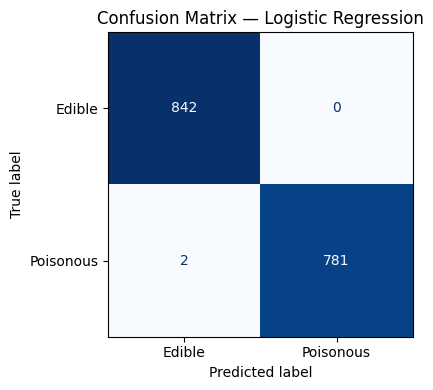


Decision Tree
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



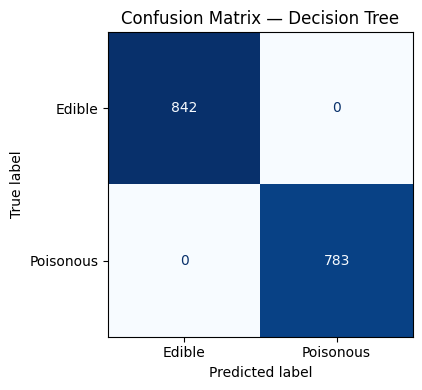


K-Nearest Neighbors
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



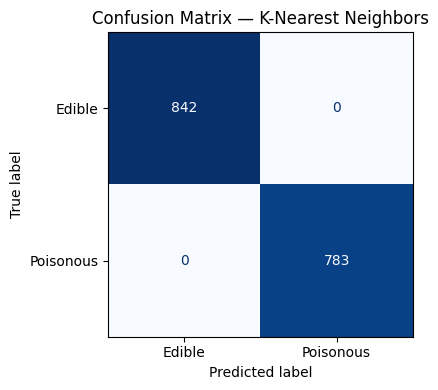


Gaussian Naive Bayes
              precision    recall  f1-score   support

      Edible     0.9974    0.9192    0.9567       842
   Poisonous     0.9199    0.9974    0.9571       783

    accuracy                         0.9569      1625
   macro avg     0.9587    0.9583    0.9569      1625
weighted avg     0.9601    0.9569    0.9569      1625



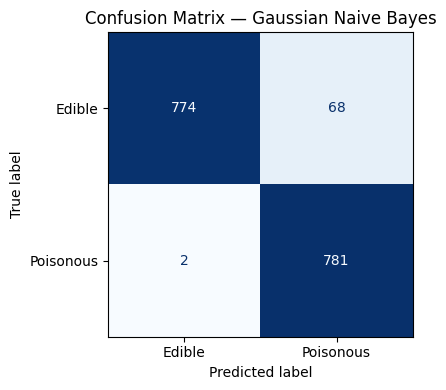


Support Vector Machine
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



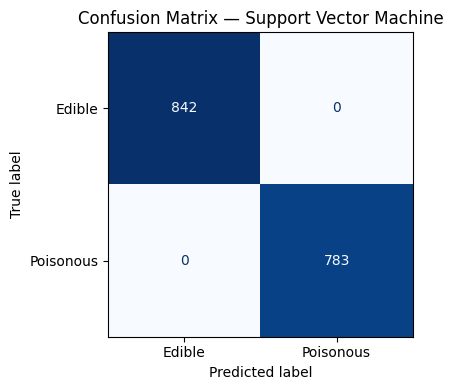

In [8]:
for model_name, y_pred in predictions.items():
    print("\n" + "=" * 75)
    print(model_name)
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Edible", "Poisonous"],
        zero_division=0,
        digits=4
    ))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Edible", "Poisonous"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 9. Model comparison, winner, and data-driven observations

Model ranking (F1, then MCC, then Accuracy):


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,K-Nearest Neighbors,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,Support Vector Machine,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
3,Logistic Regression,0.998769,1.000000,1.000000,0.997446,0.998721,0.997538
4,Gaussian Naive Bayes,0.956923,0.996294,0.919906,0.997446,0.957108,0.917007



Logistic Regression: Accuracy was 0.9988, AUC was 1.0000, precision was 1.0000, recall was 0.9974, F1 was 0.9987, and MCC was 0.9975. The model identified almost all poisonous samples in this test split. The MCC indicates exceptionally strong agreement between predictions and actual labels.

Decision Tree: Accuracy was 1.0000, AUC was 1.0000, precision was 1.0000, recall was 1.0000, F1 was 1.0000, and MCC was 1.0000. The model identified almost all poisonous samples in this test split. The MCC indicates exceptionally strong agreement between predictions and actual labels.

K-Nearest Neighbors: Accuracy was 1.0000, AUC was 1.0000, precision was 1.0000, recall was 1.0000, F1 was 1.0000, and MCC was 1.0000. The model identified almost all poisonous samples in this test split. The MCC indicates exceptionally strong agreement between predictions and actual labels.

Gaussian Naive Bayes: Accuracy was 0.9569, AUC was 0.9963, precision was 0.9199, recall was 0.9974, F1 was 0.9571, and MCC was

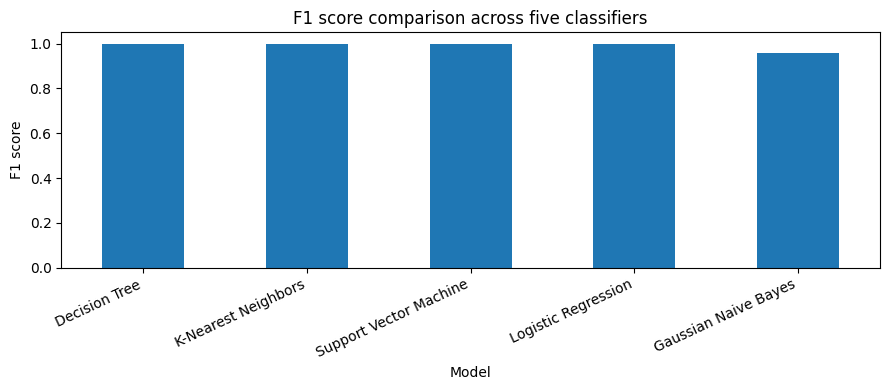

In [9]:
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
best_model_name = results_df.iloc[0]["ML Model Name"]

print("Model ranking (F1, then MCC, then Accuracy):")
display(results_df[["ML Model Name"] + metric_columns])

observations = {}
for _, row in results_df.iterrows():
    name = row["ML Model Name"]
    observations[name] = (
        f"Accuracy was {row['Accuracy']:.4f}, AUC was {row['AUC']:.4f}, "
        f"precision was {row['Precision']:.4f}, recall was {row['Recall']:.4f}, "
        f"F1 was {row['F1']:.4f}, and MCC was {row['MCC']:.4f}. "
    )
    if row["Recall"] >= 0.99:
        observations[name] += "The model identified almost all poisonous samples in this test split. "
    elif row["Recall"] < 0.90:
        observations[name] += "The model missed a comparatively larger share of poisonous samples; inspect its false negatives. "
    if row["Precision"] < 0.95:
        observations[name] += "Its precision is comparatively lower, indicating more edible samples may be flagged as poisonous. "
    if row["MCC"] >= 0.99:
        observations[name] += "The MCC indicates exceptionally strong agreement between predictions and actual labels."
    elif row["MCC"] < 0.90:
        observations[name] += "Its MCC indicates weaker overall balanced classification agreement than the leading models."

for name in classifiers:
    print(f"\n{name}: {observations[name]}")

top_rows = results_df[
    (results_df["F1"].round(12) == results_df.iloc[0]["F1"].round(12)) &
    (results_df["MCC"].round(12) == results_df.iloc[0]["MCC"].round(12)) &
    (results_df["Accuracy"].round(12) == results_df.iloc[0]["Accuracy"].round(12))
]
if len(top_rows) > 1:
    print("\nTop models are tied on F1, MCC, and Accuracy at the precision shown:")
    print(", ".join(top_rows["ML Model Name"].tolist()))
else:
    print("\nOverall leading model:", best_model_name)

fig, ax = plt.subplots(figsize=(9, 4))
results_df.set_index("ML Model Name")["F1"].sort_values(ascending=False).plot(kind="bar", ax=ax)
ax.set_title("F1 score comparison across five classifiers")
ax.set_ylabel("F1 score")
ax.set_ylim(0, 1.05)
ax.set_xlabel("Model")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
plt.close(fig)

## 10. Export the held-out test data for Streamlit

In [10]:
test_export = X_test.copy()
test_export[TARGET] = y_test.map({0: "e", 1: "p"}).values
test_export.to_csv(PROJECT_DIR / "test.csv", index=False)

print("Exported test.csv:", test_export.shape)
display(test_export.head())

Exported test.csv: (1625, 22)


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat,class
4632,x,y,g,f,f,f,c,b,p,e,b,k,k,p,n,w,o,l,h,y,d,p
3444,x,s,w,f,c,f,c,n,u,e,b,s,s,w,w,w,o,p,n,s,d,p
1209,x,f,w,f,n,f,w,b,p,t,e,s,s,w,w,w,o,e,n,s,g,e
6880,f,s,e,f,f,f,c,n,b,t,NaN,k,s,w,w,w,o,e,w,v,p,p
4542,x,f,y,f,f,f,c,b,g,e,b,k,k,p,n,w,o,l,h,y,g,p


## 11. Save feature schema and model metadata

The schema tells the Streamlit application which columns are required, which column is the target, and how class labels should be displayed.

In [11]:
feature_schema = {
    "target_column": TARGET,
    "feature_columns": feature_columns,
    "classes": {"e": "Edible", "p": "Poisonous"},
    "label_mapping": {"e": 0, "p": 1},
    "positive_class": "Poisonous (p)",
    "removed_constant_columns": constant_columns,
    "best_model_by_f1_mcc_accuracy": best_model_name,
    "model_files": MODEL_FILES,
    "random_state": RANDOM_STATE,
    "test_size": 0.20
}

with open(MODEL_DIR / "feature_schema.json", "w", encoding="utf-8") as f:
    json.dump(feature_schema, f, indent=2)

print(json.dumps(feature_schema, indent=2))

{
  "target_column": "class",
  "feature_columns": [
    "cap-shape",
    "cap-surface",
    "cap-color",
    "bruises",
    "odor",
    "gill-attachment",
    "gill-spacing",
    "gill-size",
    "gill-color",
    "stalk-shape",
    "stalk-root",
    "stalk-surface-above-ring",
    "stalk-surface-below-ring",
    "stalk-color-above-ring",
    "stalk-color-below-ring",
    "veil-color",
    "ring-number",
    "ring-type",
    "spore-print-color",
    "population",
    "habitat"
  ],
  "classes": {
    "e": "Edible",
    "p": "Poisonous"
  },
  "label_mapping": {
    "e": 0,
    "p": 1
  },
  "positive_class": "Poisonous (p)",
  "removed_constant_columns": [
    "veil-type"
  ],
  "best_model_by_f1_mcc_accuracy": "Decision Tree",
  "model_files": {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "K-Nearest Neighbors": "k_nearest_neighbors.joblib",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.joblib",
    "Support Vector Mach